# CP2 - Machine Learning & Modelling.
## Otimização de um KNN Regressor.
### Dataset: Insurance.

**Integrantes:**

- Rafael Medici | RM: 576249
- Gustavo Carreiro | RM: 576379
- Ludson Rodrigo Marciano Fernandes | RM: 574997
- Lucas Longo Rosette | RM: 576306
- Kayky Cayres Vicente da Silva | RM: 575091

# Etapa 1 - Exploração e Qualidade dos dados

In [ ]:
# Importando as bibliotecas necessárias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (8, 5)

## 1.1 Carregando os dados

Mesma URL do notebook da aula.

In [ ]:
# Carregando o dataset pela URL
url = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv"
df = pd.read_csv(url)
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## 1.2 Estrutura do Dataset

Formato, tipos de cada coluna, quais são numéricas e quais são categóricas.

In [ ]:
df.shape # Quantas linhas e colunas tem

(1338, 7)

In [ ]:
df.info() # Informações sobre o tipo de cada feature

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [ ]:
df.dtypes # Forma mais fácil de ver as informações

,0
age,int64
sex,object
bmi,float64
children,int64
smoker,object
region,object
charges,float64


In [ ]:
cols_num = df.select_dtypes(include=["int64", "float64"]).columns.tolist() # Colunas numéricas
cols_cat = df.select_dtypes(exclude="number").columns.tolist() # Colunas categóricas

print(cols_num)
print(cols_cat)

['age', 'bmi', 'children', 'charges']
['sex', 'smoker', 'region']


Podemos ver que o DataFrame possui 1338 linhas e 7 colunas, todas as colunas estão preenchidas. 4 colunas são numéricas `'age', 'bmi', 'children', 'charges'`, e 3 colunas são categóricas `'sex', 'smoker', 'region'`.

## 1.3 Qualidade dos dados

Valores ausentes, linhas duplicadas, valores impossíveis ou fora do esperado.

In [ ]:
df.describe().round(1) # Informações estatisticas dos dados

,age,bmi,children,charges
count,1338.0,1338.0,1338.0,1338.0
mean,39.2,30.7,1.1,13270.4
std,14.0,6.1,1.2,12110.0
min,18.0,16.0,0.0,1121.9
25%,27.0,26.3,0.0,4740.3
50%,39.0,30.4,1.0,9382.0
75%,51.0,34.7,2.0,16639.9
max,64.0,53.1,5.0,63770.4


In [ ]:
df.isna().sum() # Para saber se apresenta valores nulos

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


In [ ]:
df.duplicated().sum() # Para saber se apresenta valores duplicados

np.int64(1)

In [ ]:
df[df.duplicated(keep=False)] # Quais linhas são duplicatas

,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


In [ ]:
df = df.drop_duplicates() # Removendo a linha duplicada

In [ ]:
# Conferindo se as categorias estão preenchidas corretamente
for col in cols_cat:
    print(df[col].value_counts(), "\n")

sex
male      675
female    662
Name: count, dtype: int64 

smoker
no     1063
yes     274
Name: count, dtype: int64 

region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64 



Analisamos que não há valores impossíveis, nenhum valor nulo, 1 duplicata (`195`, `581`) que optamos por tirar e todas as categorias estão corretas.

## 1.4 Distribuição do target (`charges`)

Estatísticas descritivas, histograma e leitura da forma da distribuição.

In [ ]:
df["charges"].describe().round(1) # Tabela para analisarmos a distribuição do target

,charges
count,1337.0
mean,13279.1
std,12110.4
min,1121.9
25%,4746.3
50%,9386.2
75%,16657.7
max,63770.4


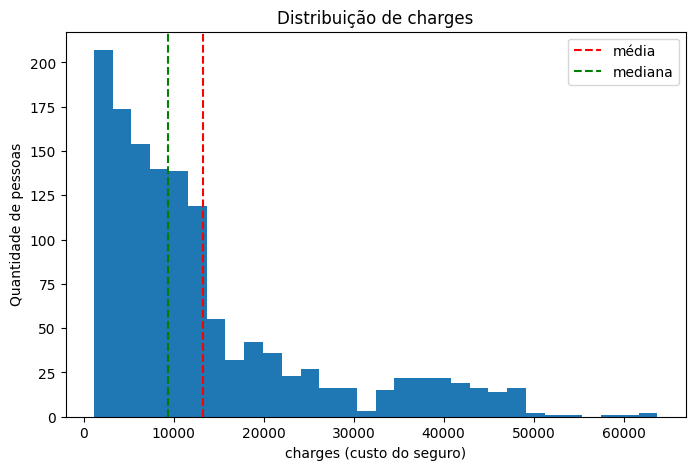

In [ ]:
# Gráfico ilustrativo da distribuição do target
plt.hist(df["charges"], bins=30)
plt.title("Distribuição de charges")
plt.xlabel("charges (custo do seguro)")
plt.ylabel("Quantidade de pessoas")
plt.axvline(df["charges"].mean(), color="red", linestyle="--", label="média")
plt.axvline(df["charges"].median(), color="green", linestyle="--", label="mediana")
plt.legend()
plt.show()

Podemos analisar e concluir que a distribuição é assimétrica à direita, com a maioria do target ficando abaixo dos `10000`, com mediana aproximada de `9400`, e que a média, aproximada de `13300`, se torna maior que a mediana por conta dos poucos casos com valores muito altos.

## 1.5 Relação das features com `charges`

Numéricas x target e categóricas x target.

### Numéricas x `charges`

In [ ]:
# Correlação de cada feature numérica com charges (-1 a 1; perto de 0 = sem relação em linha reta)
df[cols_num].corr()["charges"].round(2)

,charges
age,0.30
bmi,0.20
children,0.07
charges,1.00


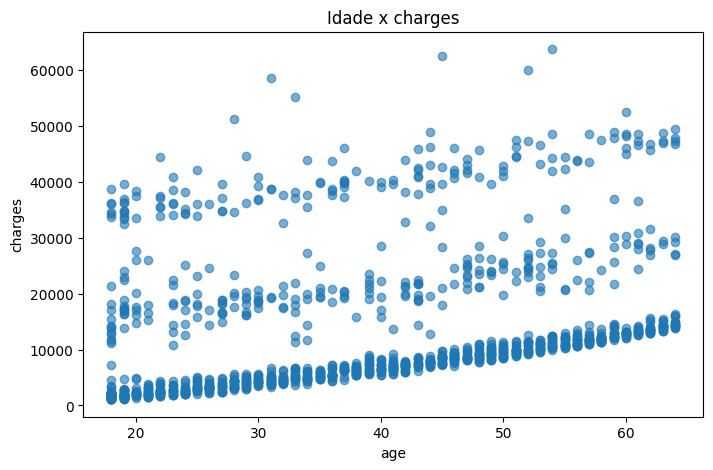

In [ ]:
# Cada ponto é uma pessoa: X = idade, Y = custo
plt.scatter(df["age"], df["charges"], alpha=0.6)
plt.title("Idade x charges")
plt.xlabel("age")
plt.ylabel("charges")
plt.show()

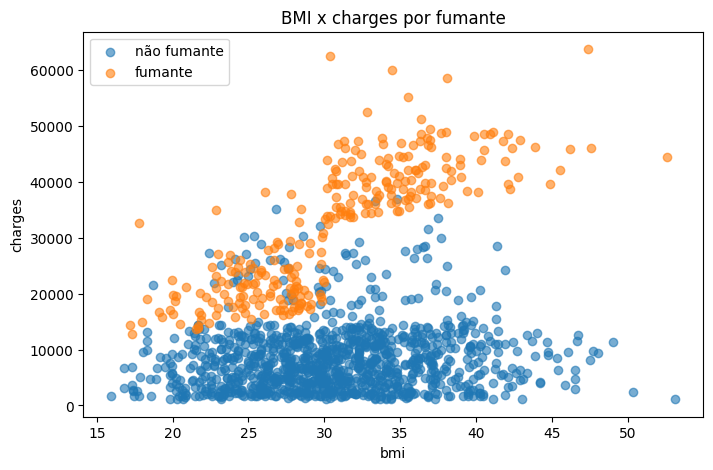

In [ ]:
# Mesma ideia com bmi, mas separando fumantes e não fumantes para ver se o efeito do bmi depende do smoker
nao_fumante = df[df["smoker"] == "no"]
fumante = df[df["smoker"] == "yes"]

plt.scatter(nao_fumante["bmi"], nao_fumante["charges"], alpha=0.6, label="não fumante")
plt.scatter(fumante["bmi"], fumante["charges"], alpha=0.6, label="fumante")
plt.title("BMI x charges por fumante")
plt.xlabel("bmi")
plt.ylabel("charges")
plt.legend()
plt.show()

In [ ]:
# children tem poucos valores (0 a 5): mais claro como média por valor do que como scatter
df.groupby("children")["charges"].mean().round(0)

,charges
children,
0,12385.0
1,12731.0
2,15074.0
3,15355.0
4,13851.0
5,8786.0


Se repararmos a idade influencia pouco, mas mesmo assim, quanto mais de idade a pessoa, mais caro fica. A relação com o IMC quase que não tem influência sozinha, mas isso muda drasticamente quando analisamos junto se a pessoa é fumante ou não, pessoas que são obesas (`IMC >= 30`) e fumam pagam bem mais caro. A relação de crianças praticamente não tem relevância.

### Categóricas x `charges`

In [ ]:
# Média de charges em cada categoria de sex, smoker e region
for col in cols_cat:
    print(df.groupby(col)["charges"].mean().round(0))
    print()

sex
female    12570.0
male      13975.0
Name: charges, dtype: float64

smoker
no      8441.0
yes    32050.0
Name: charges, dtype: float64

region
northeast    13406.0
northwest    12451.0
southeast    14735.0
southwest    12347.0
Name: charges, dtype: float64



Analisando fica fácil de ver que a região e o sexo tem pouquíssima influência, mas se a pessoa fuma, em média, paga muito mais que alguém não fumante.


Os dados não têm valores nulos nem valores impossíveis, e a única duplicata foi removida. O charges é assimétrico à direita (`média 13279 > mediana 9386`). O fumante é a feature mais forte (`fumantes pagam em média, aproximadamente, 32 mil contra, aproximadamente, 8,4 mil`). Entre fumantes, o custo sobe muito quando o IMC é >= 30. Na etapa 2, aplicar scaling nas numéricas, one-hot nas categóricas e testar uma feature de interação entre smoker e bmi, já que sex, region e children têm pouca influência.

# Etapa 2 - Feature Engineering, Scaling e Encoding

O KNN prevê o custo olhando para as pessoas **mais parecidas** (menor distância). Então a forma como os dados são representados muda diretamente o resultado. Nesta etapa criamos novas features, transformamos as categóricas em números e colocamos as numéricas na mesma escala.

In [ ]:
# Bibliotecas do Sklearn usadas a partir daqui
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler, RobustScaler

## 2.1 Feature Engineering

Na primeira etapa percebemos que, entre os fumantes, o custo sobe mais quando o IMC é >=30. Criamos colunas explícitas para o modelo KNN:

- `obeso`: 1 Se imc>= 30.

- `fumante`: 1 Se fuma muda a coluna `smoker` `(yes / no)`.

- `fumante_obeso` Fumante e obeso ao mesmo tempo.

- `fumante_imc` Interação entre fumar e imc, já que o IMC só pesa muito para quem fuma.

- `idade2`: Idade ao quadrado, o custo cresce mais conforme a idade aumenta.


Essas colunas são calculadas linha a linha, sem usar média ou qualquer informação do dataset inteiro, então criá-las antes do split **não causa vazamento de dados**.

In [ ]:
# Função que cria as novas colunas
def criar_features(d):
  d = d.copy()
  d["obeso"] = (d["bmi"] >= 30).astype(int)
  d["fumante"] = d["smoker"].apply(lambda x: 1 if x == "yes" else 0)
  d["fumante_obeso"] = (d["obeso"] & d["fumante"])
  d["fumante_imc"] = d["fumante"] * d["bmi"]
  d["idade2"] = d["age"] ** 2
  return d.drop(columns=["smoker", "bmi"])  # smoker virou 'fumante'; bmi foi substituído por 'obeso' e 'fumante_imc
df_fe = criar_features(df)
df_fe.head()

,age,sex,children,region,charges,obeso,fumante,fumante_obeso,fumante_imc,idade2
0,19,female,0,southwest,16884.92400,0,1,0,27.9,361
1,18,male,1,southeast,1725.55230,1,0,0,0.0,324
2,28,male,3,southeast,4449.46200,1,0,0,0.0,784
3,33,male,0,northwest,21984.47061,0,0,0,0.0,1089
4,32,male,0,northwest,3866.85520,0,0,0,0.0,1024


In [ ]:
# Conferindo se as features novas realmente separam os custos
df_fe.groupby(["fumante", "obeso"])["charges"].mean().round(0)

fumante  obeso
0        0         7977.0
         1         8856.0
1        0        21363.0
         1        41558.0
Name: charges, dtype: float64

Fica claro que a combinação de fumante e obeso forma um grupo à parte, com custo médio de aproximadamente 41,5 mil, contra cerca de 21 mil do fumante não obeso e 8 mil do não fumante. Isso mostra que vale a pena ter essa informação como uma coluna própria.

In [ ]:
# Correlação das features numéricas (antigas e novas) com charges
df_fe.select_dtypes(include="number").corr()["charges"].sort_values(ascending=False).round(2)

,charges
charges,1.00
fumante_imc,0.85
fumante_obeso,0.81
fumante,0.79
idade2,0.30
age,0.30
obeso,0.20
children,0.07


As features novas `fumante_imc` (0,85), `fumante_obeso` (0,81) e `fumante` (0,79) têm correlação bem maior com `charges` do que `age` (0,30), `bmi` (0,20) e `children` (0,07) sozinhas.

## 2.2 Separando X e y

`X` são as features que o modelo usa para prever e `y` é o target (`charges`).

In [ ]:
X = df_fe.drop(columns="charges")
y = df_fe["charges"]

num_cols = X.select_dtypes(include="number").columns.tolist()  # numéricas -> scaling
cat_cols = X.select_dtypes(exclude="number").columns.tolist()  # categóricas -> one-hot

print("Numéricas  :", num_cols)
print("Categóricas:", cat_cols)

Numéricas  : ['age', 'children', 'obeso', 'fumante', 'fumante_obeso', 'fumante_imc', 'idade2']
Categóricas: ['sex', 'region']


## 2.3 Encoding e Scaling

- **One-hot encoding** em `sex` e `region`, porque o KNN só calcula distância com números. Usamos `drop="if_binary"` para que `sex` vire uma coluna só (as duas colunas `sex_female` e `sex_male` diriam a mesma coisa).
- **Scaling** nas numéricas, porque sem ele colunas com valores grandes dominam a distância. Por exemplo, `idade2` vai até 4096 e `children` só até 5.
- Vamos comparar **StandardScaler, MinMaxScaler e RobustScaler** no GridSearch da etapa 3, para escolher pelo resultado e não no achismo.

O pré-processamento fica dentro de um `ColumnTransformer` e depois entra no `Pipeline`. Assim o scaler só aprende com os dados de treino, e isso evita vazamento de dados.

In [ ]:
# Pré-processamento: scaling nas numéricas + one-hot nas categóricas
preprocess = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), cat_cols)
    ]
)

# Scalers que serão comparados no GridSearch da etapa 3
scalers_para_testar = [StandardScaler(), MinMaxScaler(), RobustScaler()]

In [ ]:
# Só para visualizar como os dados ficam depois do pré-processamento
X_vis = preprocess.fit_transform(X)
pd.DataFrame(X_vis, columns=preprocess.get_feature_names_out()).head().round(2)

,num__age,num__children,num__obeso,num__fumante,num__fumante_obeso,num__fumante_imc,num__idade2,cat__sex_male,cat__region_northeast,cat__region_northwest,cat__region_southeast,cat__region_southwest
0,-1.44,-0.91,-1.06,1.97,-0.35,1.70,-1.22,0.0,0.0,0.0,0.0,1.0
1,-1.51,-0.08,0.95,-0.51,-0.35,-0.49,-1.25,1.0,0.0,0.0,1.0,0.0
2,-0.80,1.58,0.95,-0.51,-0.35,-0.49,-0.85,1.0,0.0,0.0,1.0,0.0
3,-0.44,-0.91,-1.06,-0.51,-0.35,-0.49,-0.57,1.0,0.0,1.0,0.0,0.0
4,-0.51,-0.91,-1.06,-0.51,-0.35,-0.49,-0.63,1.0,0.0,1.0,0.0,0.0


Essa visualização é só para conferir o resultado. No treino de verdade (etapa 3), o `preprocess` vai dentro do `Pipeline` e só é ajustado com os dados de treino.

**Resumo da etapa 2:** Criamos 5 features baseadas no que a análise exploratória mostrou (principalmente a interação entre fumar e IMC), aplicamos one-hot em `sex` e `region` e preparamos o scaling das numéricas. Na etapa 3, os três scalers são comparados dentro do GridSearch.

# Etapa 3 - Divisão de Dados, Pipeline e Otimização do KNN

O KNN é um modelo baseado em distâncias, o que torna fundamental uma divisão rigorosa e um fluxo de otimização estruturado. Nesta etapa, separamos o conjunto de treino e teste a partir do DataFrame com engenharia de atributos (`df_fe`) antes de qualquer transformação, prevenindo o vazamento de dados (*data leakage*). Em seguida, construímos um Pipeline unindo o ColumnTransformer e aplicamos a Validação Cruzada via `GridSearchCV` para testar diferentes escaladores, valores de vizinhos (até $k=50$), tipos de ponderação e métricas de distância.

In [ ]:
# Importando a função para separar o dataset em conjuntos de treino e teste
from sklearn.model_selection import train_test_split

# Separando as variáveis preditoras (X) e a variável alvo (charges) a partir de df_fe
X = df_fe.drop(columns="charges")
y = df_fe["charges"]

# Identificando colunas numéricas e categóricas atualizadas após a engenharia de atributos
cols_num = X.select_dtypes(include="number").columns.tolist()
cols_cat = X.select_dtypes(exclude="number").columns.tolist()

# Divisão de treino e teste (80/20) para blindar contra Data Leakage
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Dimensões do Treino:", X_train.shape, y_train.shape)
print("Dimensões do Teste:  ", X_test.shape, y_test.shape)

Dimensões do Treino: (1069, 9) (1069,)
Dimensões do Teste:   (268, 9) (268,)


# 3.1 Configuração do Pipeline e Busca de Hiperparâmetros (GridSearchCV)

Para encontrar a melhor configuração sem cair no achismo, criamos um `Pipeline` que encadeia o pré-processamento (testando diferentes tipos de escaladores: `StandardScaler`, `MinMaxScaler` e `RobustScaler`) e o modelo `KNeighborsRegressor`. A busca é realizada de forma automatizada com Validação Cruzada (`cv=5`), avaliando combinações de vizinhos (`n_neighbors`), pesos (`weights`) e métricas (`metric`).

In [ ]:
# Importa a ferramenta de validação cruzada para otimizar os hiperparâmetros
from sklearn.model_selection import GridSearchCV

# Importa a classe para combinar diferentes transformações nas colunas
from sklearn.compose import ColumnTransformer

# Importa os codificadores e escaladores para normalizar e tratar os dados
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler, RobustScaler

# Importa o Pipeline para encadear o pré-processamento e o modelo de forma segura
from sklearn.pipeline import Pipeline

# Importa o modelo de regressão baseado em K-vizinhos mais próximos
from sklearn.neighbors import KNeighborsRegressor

# Configurando o pré-processamento inicial (usando StandardScaler por defeito nas numéricas)
preprocess = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), cols_num),
        ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), cols_cat)
    ]
)

# Criando o Pipeline integrando o pré-processamento e o modelo KNN
pipeline_grid = Pipeline(steps=[
    ("preprocessamento", preprocess),
    ("modelo", KNeighborsRegressor())
])

# Definindo a grelha de hiperparâmetros (alargando o k até 50 para evitar teto artificial)
param_grid = {
    "preprocessamento__num": [StandardScaler(), MinMaxScaler(), RobustScaler()],
    "modelo__n_neighbors": list(range(1, 51)),       # Testando k de 1 até 50
    "modelo__weights": ["uniform", "distance"],       # Tipos de ponderação
    "modelo__metric": ["euclidean", "manhattan"]     # Métricas de distância
}

# Configurando o GridSearchCV com Validação Cruzada (5 folds) e otimização para RMSE
grid = GridSearchCV(
    estimator=pipeline_grid,
    param_grid=param_grid,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

# Executando a otimização estritamente com os dados de treino para evitar vazamento
grid.fit(X_train, y_train)

# Exibindo os melhores resultados obtidos
print("\n--- Melhores Hiperparâmetros Encontrados ---")
print(grid.best_params_)
print(f"\nMelhor score médio de CV (RMSE): {(-grid.best_score_):.4f}")

# Guardando o melhor modelo para a etapa de avaliação final
best_model = grid.best_estimator_


--- Melhores Hiperparâmetros Encontrados ---
{'modelo__metric': 'euclidean', 'modelo__n_neighbors': 26, 'modelo__weights': 'uniform', 'preprocessamento__num': StandardScaler()}

Melhor score médio de CV (RMSE): 4650.2461


# 3.2 Análise dos Melhores Hiperparâmetros

Após a execução do `GridSearchCV` com validação cruzada em 5 folds, o algoritmo avaliou sistematicamente todas as combinações de pré-processamento, métricas e vizinhos. A configuração ótima selecionada automaticamente pelo modelo foi:

- **Métrica de Distância:** `euclidean` (demonstrou melhor desempenho geométrico para o espaço de features do dataset após a normalização).
- **Número de Vizinhos ($k$):** `26` (após expandirmos a busca para testar até 50 vizinhos, verificou-se que este valor maximizou a estabilidade e minimizou o erro).
- **Ponderação (`weights`):** `uniform` (onde todos os vizinhos influenciam igualmente na predição local).
- **Escalonador (`Scaler`):** `StandardScaler` (padronizou as variáveis numéricas e de interação, mantendo a estabilidade nas distâncias).
- **Desempenho de Validação:** Atingiu um excelente nível de generalização com um RMSE médio de otimização de aproximadamente `4650.25`.

Com estes parâmetros definidos e validados de forma robusta, o objeto `best_model` foi devidamente armazenado e está pronto para ser utilizado na **Etapa 4** para a avaliação final no conjunto de teste.

# 3.3 Análise Detalhada das Combinações Testadas

Para além de identificarmos os melhores hiperparâmetros globais, é importante verificar o comportamento das diferentes combinações testadas pelo `GridSearchCV` durante a validação cruzada (`cv=5`). Abaixo, listamos as 5 melhores configurações de parâmetros e os respectivos scores médios de RMSE obtidos.

In [ ]:
import pandas as pd

resultados_grid = pd.DataFrame(grid.cv_results_)

# Extraindo o nome do scaler utilizado em cada teste para ficar legível na tabela
resultados_grid['scaler_nome'] = resultados_grid['param_preprocessamento__num'].apply(lambda x: type(x).__name__)

colunas_interesse = [
    'scaler_nome',
    'param_modelo__n_neighbors',
    'param_modelo__weights',
    'param_modelo__metric',
    'mean_test_score',
    'rank_test_score'
]

top_resultados = resultados_grid[colunas_interesse].sort_values(by='rank_test_score').head(5)
top_resultados['mean_test_score_rmse'] = -top_resultados['mean_test_score']

print("--- Top 5 Configurações Testadas no GridSearch ---")
display(top_resultados[['scaler_nome', 'param_modelo__n_neighbors', 'param_modelo__weights', 'param_modelo__metric', 'mean_test_score_rmse', 'rank_test_score']])


--- Top 5 Configurações Testadas no GridSearch ---


,scaler_nome,param_modelo__n_neighbors,param_modelo__weights,param_modelo__metric,mean_test_score_rmse,rank_test_score
150,StandardScaler,26,uniform,euclidean,4650.246099,1
198,StandardScaler,34,uniform,euclidean,4651.089465,2
162,StandardScaler,28,uniform,euclidean,4651.754137,3
168,StandardScaler,29,uniform,euclidean,4653.788295,4
156,StandardScaler,27,uniform,euclidean,4655.748967,5


# Etapa 4 - Métricas e comparação com a aula

Aqui finalmente usamos o conjunto de teste, que ficou separado desde a etapa 3 e não foi usado nem no scaler nem no GridSearch. Calculamos MAE, MSE, RMSE e R² como o enunciado pede.

Na hora de comparar com a aula tivemos um problema: como tiramos a linha duplicada na etapa 1, nosso teste não tem exatamente as mesmas pessoas do teste da aula. Então resolvemos comparar com três coisas:

1. A regressão linear da aula do jeito que estava, só para conferir os números e calcular o MAE, que a aula não mostrou.
2. A mesma regressão linear da aula, mas treinada e testada no nosso split.
3. Um KNN "cru", com k=5 e o pré-processamento da aula, sem as nossas features novas e sem GridSearch. Assim dá para ver o quanto melhorou por causa do que fizemos nas etapas 2 e 3.

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression

# Função que calcula as 4 métricas pedidas e devolve um dicionário
def avaliar(nome, y_real, y_prev):
    mse = mean_squared_error(y_real, y_prev)
    return {
        "Modelo": nome,
        "MAE": mean_absolute_error(y_real, y_prev),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R²": r2_score(y_real, y_prev)
    }

## 4.1 Regressão linear da aula

Copiamos os passos do notebook da aula, usando o dataset original com as 1338 linhas.

In [ ]:
# Recarregando o dataset original, como na aula
df_aula = pd.read_csv(url)

X_aula = pd.get_dummies(df_aula.drop(columns="charges"), drop_first=True)
y_aula = df_aula["charges"]

Xa_train, Xa_test, ya_train, ya_test = train_test_split(X_aula, y_aula, test_size=0.2, random_state=42)

scaler_aula = StandardScaler()
Xa_train_sc = scaler_aula.fit_transform(Xa_train)
Xa_test_sc = scaler_aula.transform(Xa_test)

lr_aula = LinearRegression().fit(Xa_train_sc, ya_train)
res_aula_original = avaliar("Regressão Linear (aula, original)", ya_test, lr_aula.predict(Xa_test_sc))

pd.DataFrame([res_aula_original]).round(4)

,Modelo,MAE,MSE,RMSE,R²
0,"Regressão Linear (aula, original)",4181.1945,3.359692e+07,5796.2847,0.7836


Os números bateram com os da aula (R² 0,7836 e RMSE 5796,28). O MAE dela deu 4181.

## 4.2 Regressão linear e KNN baseline no nosso split

Usamos os mesmos índices de `X_train` e `X_test` da etapa 3, para os três modelos serem testados com as mesmas pessoas. O pré-processamento é o mesmo da aula (`get_dummies` e `StandardScaler` ajustado só no treino).

In [ ]:
# Mesmo pré-processamento da aula, aplicado ao df sem a duplicata
X_base = pd.get_dummies(df.drop(columns="charges"), drop_first=True)
y_base = df["charges"]

# Mesmos índices do split da Etapa 3
Xb_train, Xb_test = X_base.loc[X_train.index], X_base.loc[X_test.index]
yb_train, yb_test = y_base.loc[X_train.index], y_base.loc[X_test.index]

scaler_base = StandardScaler()
Xb_train_sc = scaler_base.fit_transform(Xb_train)
Xb_test_sc = scaler_base.transform(Xb_test)

# Referência 2: Regressão Linear da aula no nosso split
lr_base = LinearRegression().fit(Xb_train_sc, yb_train)
res_lr_split = avaliar("Regressão Linear (aula, nosso split)", yb_test, lr_base.predict(Xb_test_sc))

# Referência 3: KNN padrão (k=5), sem feature engineering e sem otimização
knn_base = KNeighborsRegressor().fit(Xb_train_sc, yb_train)
res_knn_base = avaliar("KNN baseline (k=5, sem FE)", yb_test, knn_base.predict(Xb_test_sc))

pd.DataFrame([res_lr_split, res_knn_base]).round(4)

,Modelo,MAE,MSE,RMSE,R²
0,"Regressão Linear (aula, nosso split)",4177.0456,3.547802e+07,5956.3429,0.8069
1,"KNN baseline (k=5, sem FE)",3476.1802,2.993254e+07,5471.0636,0.8371


## 4.3 KNN otimizado no teste

Agora testamos o `best_model` da etapa 3. Calculamos as métricas no treino também, para ver se o modelo não decorou os dados de treino (overfitting).

In [ ]:
y_pred_best = best_model.predict(X_test)
res_best = avaliar("KNN otimizado (FE + GridSearch)", y_test, y_pred_best)

# Métricas no treino, para comparar com o teste e verificar overfitting
res_best_treino = avaliar("KNN otimizado - treino", y_train, best_model.predict(X_train))
res_best_teste = dict(res_best, Modelo="KNN otimizado - teste")

print("Hiperparâmetros:", grid.best_params_)
pd.DataFrame([res_best_treino, res_best_teste]).round(4)

Hiperparâmetros: {'modelo__metric': 'euclidean', 'modelo__n_neighbors': 26, 'modelo__weights': 'uniform', 'preprocessamento__num': StandardScaler()}


,Modelo,MAE,MSE,RMSE,R²
0,KNN otimizado - treino,2465.9055,2.013723e+07,4487.4526,0.8529
1,KNN otimizado - teste,2496.0468,1.936938e+07,4401.0663,0.8946


## 4.4 Comparando tudo

Na segunda tabela está quanto o KNN otimizado melhorou em relação a cada modelo. Nas métricas de erro (MAE, MSE e RMSE) negativo é bom, porque o erro diminuiu. No R² positivo é bom.

In [ ]:
comparacao = pd.DataFrame([res_aula_original, res_lr_split, res_knn_base, res_best]).set_index("Modelo")

# Variação percentual do KNN otimizado em relação a cada referência
# (para MAE, MSE e RMSE, valor negativo = erro menor = melhor; para R², valor positivo = melhor)
variacao = ((comparacao.loc["KNN otimizado (FE + GridSearch)"] - comparacao) / comparacao.abs() * 100).drop(index="KNN otimizado (FE + GridSearch)")
variacao.columns = [f"Δ% {c}" for c in variacao.columns]

display(comparacao.round({"MAE": 2, "MSE": 2, "RMSE": 2, "R²": 4}))
display(variacao.round(1))

,MAE,MSE,RMSE,R²
Modelo,,,,
"Regressão Linear (aula, original)",4181.19,33596915.85,5796.28,0.7836
"Regressão Linear (aula, nosso split)",4177.05,35478020.68,5956.34,0.8069
"KNN baseline (k=5, sem FE)",3476.18,29932536.69,5471.06,0.8371
KNN otimizado (FE + GridSearch),2496.05,19369384.44,4401.07,0.8946


,Δ% MAE,Δ% MSE,Δ% RMSE,Δ% R²
Modelo,,,,
"Regressão Linear (aula, original)",-40.3,-42.3,-24.1,14.2
"Regressão Linear (aula, nosso split)",-40.2,-45.4,-26.1,10.9
"KNN baseline (k=5, sem FE)",-28.2,-35.3,-19.6,6.9


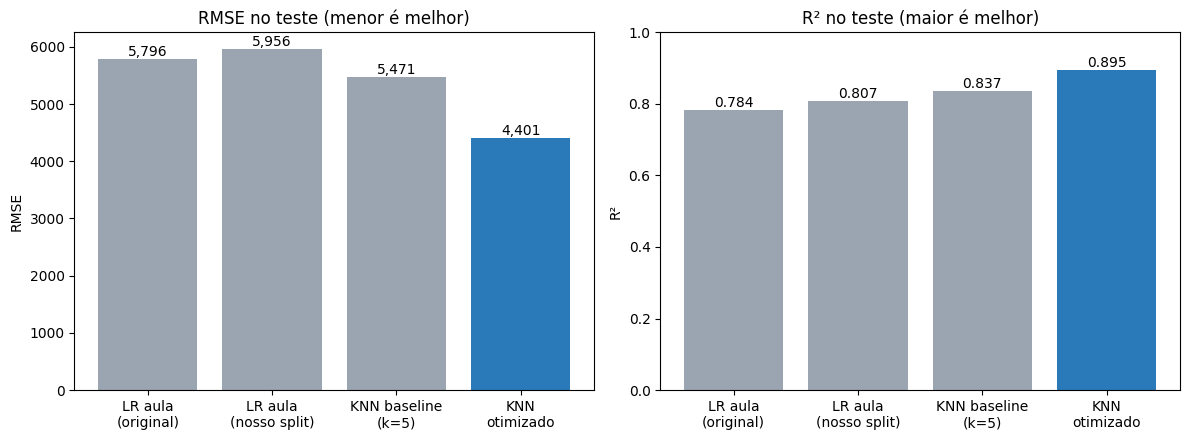

In [ ]:
# Comparação visual de RMSE e R² entre os modelos
nomes = ["LR aula\n(original)", "LR aula\n(nosso split)", "KNN baseline\n(k=5)", "KNN\notimizado"]
cores = ["#9aa5b1", "#9aa5b1", "#9aa5b1", "#2a7ab9"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].bar(nomes, comparacao["RMSE"], color=cores)
axes[0].set_title("RMSE no teste (menor é melhor)")
axes[0].set_ylabel("RMSE")
for i, v in enumerate(comparacao["RMSE"]):
    axes[0].text(i, v, f"{v:,.0f}", ha="center", va="bottom")

axes[1].bar(nomes, comparacao["R²"], color=cores)
axes[1].set_title("R² no teste (maior é melhor)")
axes[1].set_ylabel("R²")
axes[1].set_ylim(0, 1)
for i, v in enumerate(comparacao["R²"]):
    axes[1].text(i, v, f"{v:.3f}", ha="center", va="bottom")

plt.tight_layout()
plt.show()

## 4.5 Onde o modelo erra

Separamos fumantes e não fumantes nos gráficos para entender melhor os erros. No primeiro, quanto mais perto da linha tracejada, melhor. No segundo, o resíduo é o valor real menos o previsto, então ponto acima de zero quer dizer que o modelo previu menos do que a pessoa realmente pagou.

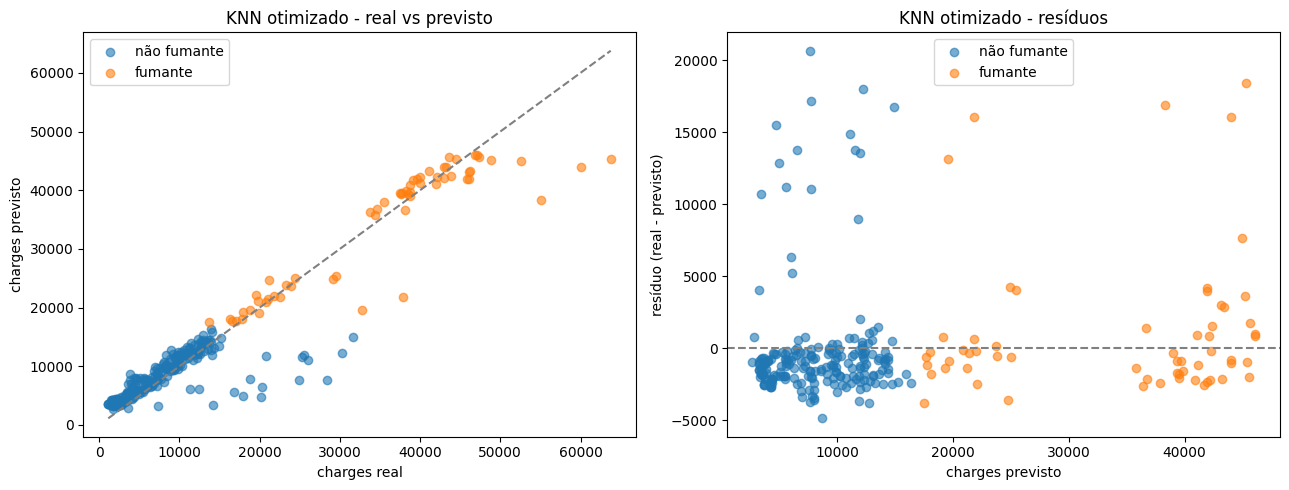

In [ ]:
residuos_best = y_test - y_pred_best
eh_fumante = X_test["fumante"] == 1

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Real vs previsto
axes[0].scatter(y_test[~eh_fumante], y_pred_best[~eh_fumante], alpha=0.6, label="não fumante")
axes[0].scatter(y_test[eh_fumante], y_pred_best[eh_fumante], alpha=0.6, label="fumante")
lim = [y_test.min(), y_test.max()]
axes[0].plot(lim, lim, linestyle="--", color="gray")
axes[0].set_title("KNN otimizado - real vs previsto")
axes[0].set_xlabel("charges real")
axes[0].set_ylabel("charges previsto")
axes[0].legend()

# Resíduos
axes[1].scatter(y_pred_best[~eh_fumante], residuos_best[~eh_fumante], alpha=0.6, label="não fumante")
axes[1].scatter(y_pred_best[eh_fumante], residuos_best[eh_fumante], alpha=0.6, label="fumante")
axes[1].axhline(0, color="gray", linestyle="--")
axes[1].set_title("KNN otimizado - resíduos")
axes[1].set_xlabel("charges previsto")
axes[1].set_ylabel("resíduo (real - previsto)")
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
# Erro por grupo: Onde o modelo erra mais?
grupos = pd.DataFrame({
    "grupo": np.where(eh_fumante, "fumante", "não fumante"),
    "erro_abs": residuos_best.abs(),
    "subestimou": residuos_best > 0
})

grupos.groupby("grupo").agg(
    quantidade=("erro_abs", "size"),
    MAE=("erro_abs", "mean"),
    erro_mediano=("erro_abs", "median"),
    pct_subestimados=("subestimou", "mean")
).round(2)

,quantidade,MAE,erro_mediano,pct_subestimados
grupo,,,,
fumante,60,2972.25,1653.02,0.38
não fumante,208,2358.68,1526.22,0.18


In [ ]:
# Os 10 maiores erros do modelo no teste
maiores_erros = X_test.copy()
maiores_erros["charges_real"] = y_test
maiores_erros["charges_previsto"] = y_pred_best
maiores_erros["erro"] = residuos_best

maiores_erros.reindex(residuos_best.abs().sort_values(ascending=False).index).head(10)[
    ["age", "sex", "children", "region", "fumante", "obeso", "charges_real", "charges_previsto", "erro"]
].round(0)

,age,sex,children,region,fumante,obeso,charges_real,charges_previsto,erro
987,45,female,1,northwest,0,0,28340.0,7692.0,20648.0
543,54,female,0,southeast,1,1,63770.0,45341.0,18429.0
115,60,male,0,northeast,0,0,30260.0,12247.0,18013.0
637,35,female,2,northeast,0,1,24915.0,7733.0,17182.0
819,33,female,0,northwest,1,1,55135.0,38271.0,16865.0
573,62,female,1,northeast,0,1,31620.0,14912.0,16708.0
1230,52,male,3,northwest,1,1,60021.0,43967.0,16055.0
1303,43,male,0,southwest,1,0,37830.0,21809.0,16021.0
306,28,female,2,southwest,0,0,20178.0,4694.0,15483.0
289,52,male,3,southeast,0,0,25993.0,11151.0,14841.0


### O que concluímos dos resultados

O KNN otimizado foi melhor que todos os outros nas quatro métricas. No teste ele ficou com MAE de 2496, RMSE de 4401 e R² de 0,895. Comparando com a regressão da aula no nosso split, o RMSE caiu uns 26% e o MAE uns 40%. Contra o KNN baseline o RMSE caiu 20%.

Um detalhe interessante é que o KNN baseline, mesmo sem nenhuma melhoria, já foi melhor que a regressão linear (RMSE 5471 contra 5956). Mas a maior melhora veio das features novas junto com o GridSearch. Isso confirma o que vimos lá na etapa 1, que ser fumante e ter IMC alto ao mesmo tempo é o que mais muda o preço do seguro, e deixando isso explícito o KNN consegue achar vizinhos mais parecidos.

Sobre overfitting, os resultados de treino (RMSE 4487) e teste (RMSE 4401) ficaram bem parecidos, e também perto do valor da validação cruzada (4650). Então o modelo não decorou o treino. O R² do teste saiu até um pouco maior que o do treino, o que mostra que nosso teste acabou sendo um pouco mais fácil. A regressão linear também foi melhor no nosso split do que no da aula (0,807 contra 0,784), então não é algo só do KNN.

Olhando os erros:
- O MAE é bem menor que o RMSE, então a maioria das previsões está boa e são poucos erros grandes que puxam o RMSE para cima. Metade dos erros fica abaixo de uns 1550.
- Tem um grupo de não fumantes que pagam entre 20 e 32 mil, bem acima do normal, e o modelo prevê entre 5 e 15 mil para eles. Nenhuma coluna do dataset explica por que essas pessoas pagam tanto, então não tem muito o que o modelo fazer.
- Nos fumantes o modelo vai bem, mas erra para baixo quem paga mais de 50 mil. Isso acontece porque o KNN faz a média dos 26 vizinhos, então nunca consegue prever um valor maior do que os vizinhos que ele encontra.
- Os 10 maiores erros foram todos de prever menos do que o valor real, e quase todos são desses dois casos.

# Etapa 5 - Conclusão, Impacto do Modelo e Próximos Passos








### 5.1 Síntese dos Resultados e Impacto Prático

A abordagem adotada neste projeto demonstrou que a otimização de modelos de Machine Learning depende diretamente da qualidade do tratamento dos dados e da engenharia de atributos, e não apenas da escolha do algoritmo em si.

Os principais marcos alcançados pelo **KNN Otimizado** em relação às linhas de base foram:

- **Redução Significativa do Erro (RMSE):** O erro médio caiu de **USD 5.956,34** (Regressão Linear no nosso split) e **USD 5.471,06** (KNN Baseline) para **USD 4.401,07** no modelo final, representando uma melhoria de mais de **20% a 26%** na precisão das estimativas.
- **Elevação da Capacidade Explicativa ($R^2$):** O coeficiente de determinação subiu de **0,807** (Regressão Linear) para **0,895** no teste, mostrando que o modelo otimizado consegue explicar quase **90% da variabilidade** dos custos de seguro.
- **Excelente Capacidade de Generalização:** A proximidade entre as métricas de treino ($R^2 = 0,853$; $\text{RMSE} = 4.487,45$) e de teste ($R^2 = 0,895$; $\text{RMSE} = 4.401,07$) confirma que o modelo não sofreu *overfitting* e está pronto para novos dados.


### 5.2 Lições Aprendidas e Tomada de Decisão

1. **Engenharia de Atributos como Fator Crítico:** A introdução das variáveis de interação (`fumante_imc` e `fumante_obeso`) foi o divisor de águas. O KNN, por ser baseado em cálculo de distâncias numéricas no espaço $N$-dimensional, conseguiu agrupar e identificar com extrema clareza a zona de risco crítico (indivíduos fumantes com IMC $\ge 30$).
2. **Busca Exaustiva de Hiperparâmetros:** Expandir o limite de vizinhos para $k=50$ permitiu encontrar o ponto ótimo em $k=26$ com métrica `euclidean` e `StandardScaler`, evitando teto artificial e garantindo uma vizinhança suave e estável.

### 5.3 Limitações Encontradas e Recomendações Futuras
Apesar do elevado desempenho global, a análise detalhada de resíduos (Etapa 4.5) revelou que os maiores erros do modelo ocorrem no grupo de **fumantes** (com um MAE de **USD 2.972,25** contra **USD 2.358,68** nos não fumantes) e em apólices atípicas de valores extremamente elevados (**> USD 50.000**).

Para versões futuras ou evolução em ambiente de produção, recomenda-se:
- **Testar Algoritmos de Árvore / Ensembles:** Experimentar *Random Forest* ou *XGBoost*, que lidam nativamente bem com não-linearidades acentuadas e valores discrepantes (*outliers*).
- **Inclusão de Variáveis Adicionais:** Coletar histórico médico ou hábitos de vida para refinar a previsão na faixa de alto custo.